# Junior Data Analyst: data analysis and anomaly detection in part images

**Background:** parts are photographed at the end of production and a human inspector labelled some images as
OK (0) or defective (1). Alerts went up recently, and it is unclear whether the cause is **part quality**,
**imaging conditions**, or **the data/labels themselves**.

**Goal:** explore the data and images, build a simple and explainable first-pass detector for suspicious images,
validate it honestly, and draw conclusions.

**How to run:** from this folder, *Run All* (or `jupyter nbconvert --to notebook --execute --inplace solution.ipynb`).
Needs numpy, pandas, opencv-python, matplotlib and scikit-learn; runs on a CPU in under a minute.

In [1]:
from pathlib import Path
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path(".")
SEED = 42
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

def read_gray(rel_path):
    # cv2.imread fails on Windows paths with non-ASCII characters (e.g. a Hebrew folder name),
    # so read the bytes with numpy and decode them with OpenCV.
    return cv2.imdecode(np.fromfile(str(DATA_DIR / rel_path), np.uint8), cv2.IMREAD_GRAYSCALE)

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
print("train:", train.shape, " test:", test.shape)
display(train.head())

train: (168, 10)  test: (72, 8)


,image_id,file,batch,line,camera,shift,timestamp_utc,exposure_setting,inspector_label,inspector_type
0,IMG_0004,images/IMG_0004.jpg,BATCH-A,LINE-1,CAM-A,DAY,2026-11-02T07:45:00Z,NORMAL,1,stain
1,IMG_0005,images/IMG_0005.jpg,BATCH-A,LINE-1,CAM-B,DAY,2026-11-02T08:00:00Z,LOW,0,none
2,IMG_0006,images/IMG_0006.jpg,BATCH-A,LINE-1,CAM-A,DAY,2026-11-02T08:15:00Z,NORMAL,1,stain
3,IMG_0007,images/IMG_0007.jpg,BATCH-A,LINE-1,CAM-B,NIGHT,2026-11-02T08:30:00Z,LOW,1,stain
4,IMG_0008,images/IMG_0008.jpg,BATCH-A,LINE-2,CAM-B,DAY,2026-11-02T08:45:00Z,NORMAL,0,none


## Part A: getting to know the data

### Data quality checks
Before any analysis: missing values, duplicate IDs, overlap between train and test, and whether every image file exists.

In [2]:
checks = {
    "missing values (train)": int(train.isna().sum().sum()),
    "missing values (test)": int(test.isna().sum().sum()),
    "duplicate image_id (train)": int(train.image_id.duplicated().sum()),
    "image_id in both train and test": len(set(train.image_id) & set(test.image_id)),
    "image files missing on disk": int(sum(not (DATA_DIR / f).exists() for f in pd.concat([train.file, test.file]))),
    "image files in images/": len(list((DATA_DIR / "images").glob("*.jpg"))),
}
display(pd.Series(checks, name="value").to_frame())
print("columns only in train:", sorted(set(train.columns) - set(test.columns)))

,value
missing values (train),0
missing values (test),0
duplicate image_id (train),0
image_id in both train and test,0
image files missing on disk,0
image files in images/,240


columns only in train: ['inspector_label', 'inspector_type']


The data is clean. Two columns exist only in train: `inspector_label` (the target) and `inspector_type`.

**Leakage trap:** `inspector_type` is the inspector's defect type, and it maps exactly onto the label
(`none` = 0, every other type = 1). It is not available for test images, so it must **never** be used as a model feature.
It is used here only to *understand* the data.

In [3]:
display(pd.crosstab(train.inspector_type, train.inspector_label, margins=True))

inspector_label,0,1,All
inspector_type,,,
edge_chip,0,14,14
missing_hole,0,9,9
none,112,0,112
scratch,0,13,13
stain,0,20,20
All,112,56,168


### A1. Number of records and label distribution

In [4]:
lab = train.inspector_label.map({0: "OK (0)", 1: "defective (1)"})
dist = pd.DataFrame({"count": lab.value_counts(), "share_%": (100 * lab.value_counts(normalize=True)).round(1)})
print(f"Labelled records: {len(train)}   |   Test records (unlabelled): {len(test)}")
display(dist)

Labelled records: 168   |   Test records (unlabelled): 72


,count,share_%
inspector_label,,
OK (0),112,66.7
defective (1),56,33.3


Two thirds of the labelled images are OK and one third is defective. The classes are imbalanced but not extremely,
so accuracy alone would be misleading (predicting "OK" for everything already gives 67 %). Precision and recall are reported in Part D.

### A2. Defect rate per camera (with number of images)

In [5]:
by_cam = (train.groupby("camera").inspector_label
               .agg(n_images="size", n_defective="sum", defect_rate="mean"))
by_cam["defect_rate_%"] = (100 * by_cam.pop("defect_rate")).round(1)
display(by_cam)

# Is a ~4-point difference meaningful with n=95 vs n=73? Rough 95% CI for each proportion:
for cam, r in by_cam.iterrows():
    p, n = r["defect_rate_%"] / 100, r.n_images
    half = 1.96 * np.sqrt(p * (1 - p) / n) * 100
    print(f"{cam}: {100*p:.1f}% ± {half:.1f} pts (95% CI)")

,n_images,n_defective,defect_rate_%
camera,,,
CAM-A,95,30,31.6
CAM-B,73,26,35.6


CAM-A: 31.6% ± 9.3 pts (95% CI)
CAM-B: 35.6% ± 11.0 pts (95% CI)


The defect rate is about the same for both cameras (31.6 % vs 35.6 %), and the confidence intervals (about ±10 points) overlap heavily.
**On their own labels, the cameras do not explain the alerts.**

The other metadata looks the same: every group is in the 30–38 % range. Batch is the only field with a wider spread:

In [6]:
rows = []
for col in ["camera", "line", "shift", "exposure_setting", "batch"]:
    g = train.groupby(col).inspector_label.agg(["size", "mean"])
    for k, r in g.iterrows():
        rows.append({"field": col, "value": k, "n": int(r["size"]), "defect_rate_%": round(100 * r["mean"], 1)})
display(pd.DataFrame(rows).set_index(["field", "value"]))
print("Camera x exposure (counts): LOW exposure exists only on CAM-B, so the two are confounded")
display(pd.crosstab(train.camera, train.exposure_setting))

n  defect_rate_%
field            value                     
camera           CAM-A    95           31.6
                 CAM-B    73           35.6
line             LINE-1   88           33.0
                 LINE-2   80           33.8
shift            DAY      82           31.7
                 NIGHT    86           34.9
exposure_setting AUTO     80           30.0
                 LOW      48           37.5
                 NORMAL   40           35.0
batch            BATCH-A  42           33.3
                 BATCH-B  42           26.2
                 BATCH-C  42           42.9
                 BATCH-D  42           31.0

Camera x exposure (counts): LOW exposure exists only on CAM-B, so the two are confounded


exposure_setting,AUTO,LOW,NORMAL
camera,,,
CAM-A,65,0,30
CAM-B,15,48,10


### A3. One chart, one insight: what kind of defect does each batch get?

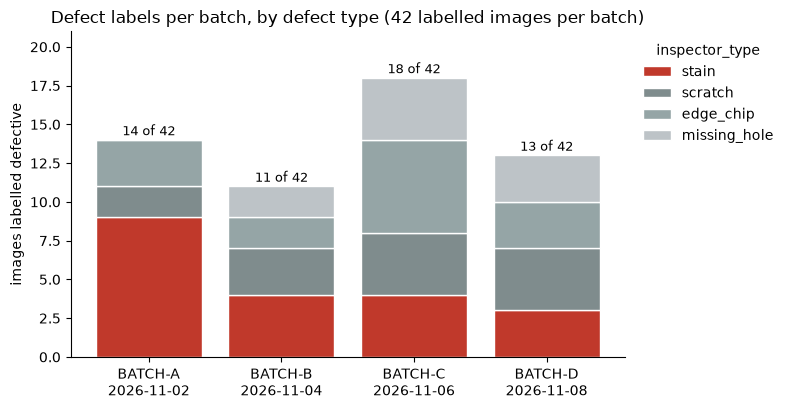

inspector_type,stain,scratch,edge_chip,missing_hole,total
batch,,,,,
BATCH-A,9,2,3,0,14
BATCH-B,4,3,2,2,11
BATCH-C,4,4,6,4,18
BATCH-D,3,4,3,3,13


In [7]:
types = ["stain", "scratch", "edge_chip", "missing_hole"]
ct = pd.crosstab(train.batch, train.inspector_type)[types]
day = train.groupby("batch").timestamp_utc.first().str[:10]

fig, ax = plt.subplots(figsize=(8, 4.2))
bottom = np.zeros(len(ct))
colors = {"stain": "#c0392b", "scratch": "#7f8c8d", "edge_chip": "#95a5a6", "missing_hole": "#bdc3c7"}
for t in types:
    ax.bar(ct.index, ct[t], bottom=bottom, color=colors[t], label=t, edgecolor="white")
    bottom += ct[t].values
for i, (b, tot) in enumerate(zip(ct.index, bottom)):
    ax.text(i, tot + 0.3, f"{int(tot)} of 42", ha="center", fontsize=9)
ax.set_xticks(range(len(ct)), [f"{b}\n{day[b]}" for b in ct.index])
ax.set_ylabel("images labelled defective"); ax.set_ylim(0, bottom.max() + 3)
ax.set_title("Defect labels per batch, by defect type (42 labelled images per batch)")
ax.legend(title="inspector_type", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()
display(ct.assign(total=ct.sum(axis=1)))

**Insight:** scratches, edge chips and missing holes are stable across batches (2–6 each). **Stains** are the outlier:
batch A (Nov 2) has **9 stain labels**, against 3–4 in every other batch.

A sudden spike in a single defect type, on a single day, while the other types stay flat, has two possible explanations:
a real (temporary) stain problem in production, or **labelling drift**, meaning the inspector marked stains more readily that day.
The metadata alone can't tell these apart, but the images can. This is checked in Part B by looking at the batch A stain images
and comparing them with an image-based anomaly score.

## Part B: understanding the images and extracting features

### B1. Six example images (OK and defective)
Two OK images and one example of each defect type. The defect examples were picked by hand because the defect is
clearly visible in them; this is for illustration only and plays no part in any prediction.

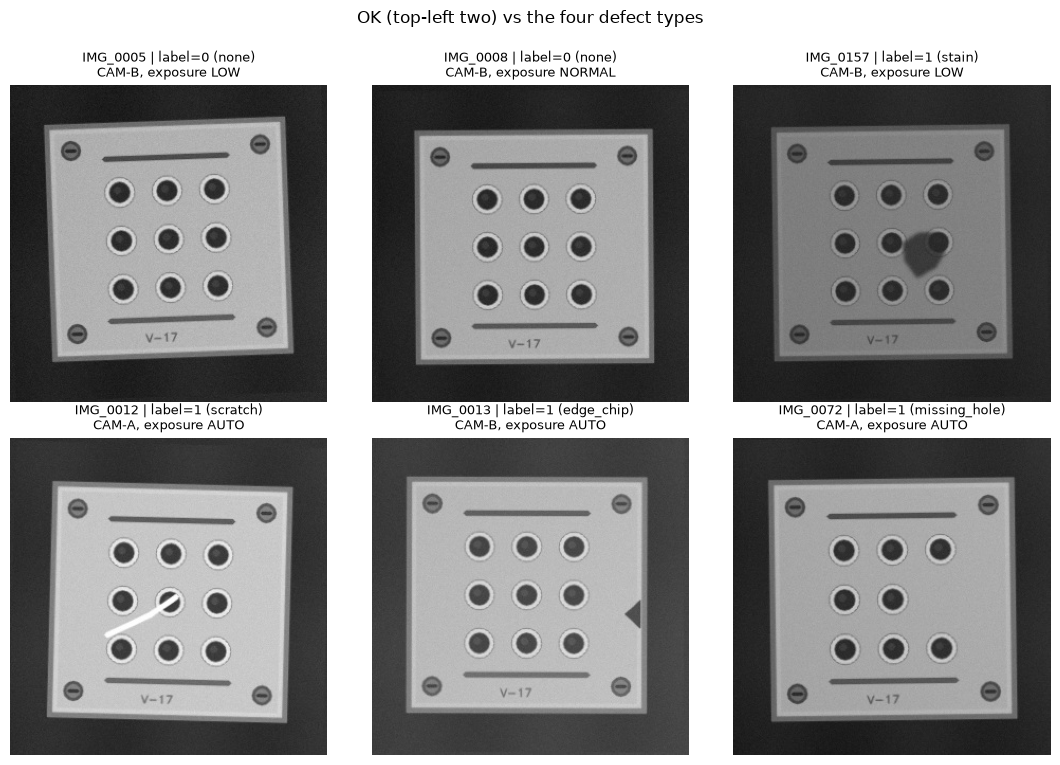

In [8]:
examples = ["IMG_0005", "IMG_0008", "IMG_0157", "IMG_0012", "IMG_0013", "IMG_0072"]
ex = train.set_index("image_id").loc[examples]
fig, axes = plt.subplots(2, 3, figsize=(11, 7.6))
for ax, (iid, r) in zip(axes.flat, ex.iterrows()):
    ax.imshow(read_gray(r.file), cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"{iid} | label={r.inspector_label} ({r.inspector_type})\n{r.camera}, exposure {r.exposure_setting}", fontsize=9)
    ax.axis("off")
plt.suptitle("OK (top-left two) vs the four defect types", y=1.0); plt.tight_layout(); plt.show()

**Visual differences:**
* Every image shows the same part: a grey square plate on a dark background, with a 3×3 grid of holes, 4 screws, 2 bars and the text "V-17".
  The plate is **slightly rotated and shifted** from image to image, and overall brightness varies with camera and exposure.
* The defects are **small and local**: a dark blob (stain, IMG_0157), a bright line across the holes (scratch, IMG_0012),
  a triangular notch cut into the plate edge (edge chip, IMG_0013) and an empty spot where a hole should be (missing hole, IMG_0072).
  Most of each image is identical between OK and defective parts.

That suggests a feature: whole-image averages (brightness, contrast) should barely react to such a small change, while a
**comparison with what a normal plate looks like** should react strongly. Both ideas are tested below.

### B2. Feature function
Two features:
1. **`anomaly_score`**, the main feature: how far the most unusual region of the plate deviates from a typical OK plate.
   1. Find the plate: Otsu threshold → largest contour → minimum-area rotated rectangle.
   2. Warp the plate to a straight 256×256 square, which removes rotation and shift.
   3. Normalise brightness (subtract the mean, divide by the std), which removes exposure differences.
   4. Smooth lightly (Gaussian, σ=2) so that tiny alignment errors and pixel noise don't count.
   5. Compare with a **template**: the pixel-wise median of OK plates. Score = the largest absolute difference,
      ignoring an 8-pixel border where alignment is least precise.
2. **`sharpness`**: variance of the Laplacian on the raw image. This is a *capture-quality* feature, not a defect feature.
   It's used to check whether blur explains errors (the brief notes that a blurry image is not necessarily a defective part).

`brightness` (mean grey level) is also returned as a reference for capture conditions.

**Avoiding leakage:** the template is built only from OK images in the **development** split. The validation images
(used in Part D) must not influence their own feature, so the 70/30 split is made here and reused in Part C.

In [9]:
from sklearn.model_selection import train_test_split

dev, val = train_test_split(train, test_size=0.30, stratify=train.inspector_label, random_state=SEED)
train["split"] = np.where(train.image_id.isin(dev.image_id), "dev", "val")
print(pd.crosstab(train.split, train.inspector_label, margins=True))

inspector_label    0   1  All
split                        
dev               78  39  117
val               34  17   51
All              112  56  168


In [10]:
SIZE, SIGMA, BORDER = 256, 2.0, 8

def _order_corners(pts):
    # top-left, top-right, bottom-right, bottom-left
    s, d = pts.sum(axis=1), np.diff(pts, axis=1).ravel()
    return np.float32([pts[np.argmin(s)], pts[np.argmin(d)], pts[np.argmax(s)], pts[np.argmax(d)]])

def align_plate(gray):
    # Locate the plate and warp it to a straight SIZE x SIZE square.
    blur = cv2.GaussianBlur(gray, (5, 5), 0)
    _, mask = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((7, 7), np.uint8))   # fill the dark holes
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    plate = max(contours, key=cv2.contourArea)
    corners = _order_corners(cv2.boxPoints(cv2.minAreaRect(plate)))
    target = np.float32([[0, 0], [SIZE - 1, 0], [SIZE - 1, SIZE - 1], [0, SIZE - 1]])
    return cv2.warpPerspective(gray, cv2.getPerspectiveTransform(corners, target), (SIZE, SIZE)).astype(np.float32)

def normalise(plate):
    z = (plate - plate.mean()) / (plate.std() + 1e-6)
    return cv2.GaussianBlur(z, (0, 0), SIGMA)

def build_template(rel_paths):
    return np.median([normalise(align_plate(read_gray(p))) for p in rel_paths], axis=0)

def anomaly_map(gray, template):
    return np.abs(normalise(align_plate(gray)) - template)

def extract_features(rel_path, template):
    # Read one image and return its numeric features.
    gray = read_gray(rel_path)
    diff = anomaly_map(gray, template)[BORDER:-BORDER, BORDER:-BORDER]
    return {"anomaly_score": float(diff.max()),
            "sharpness": float(cv2.Laplacian(gray, cv2.CV_64F).var()),
            "brightness": float(gray.mean())}

ok_dev = train[(train.split == "dev") & (train.inspector_label == 0)]
TEMPLATE = build_template(ok_dev.file)
print(f"template built from {len(ok_dev)} OK images of the development split")

template built from 78 OK images of the development split


**Sanity check:** does the anomaly map light up on the actual defect? Example images: aligned plate, template, and difference map.

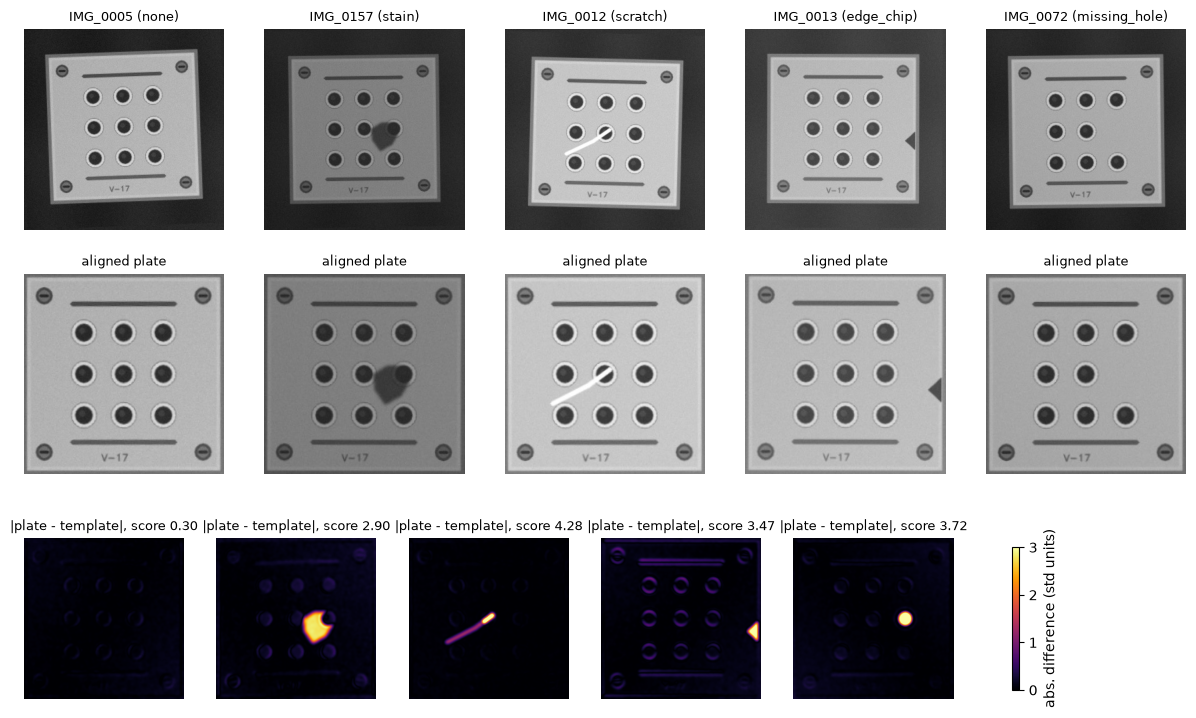

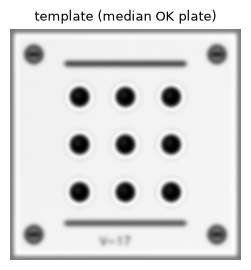

In [11]:
show_ids = ["IMG_0005", "IMG_0157", "IMG_0012", "IMG_0013", "IMG_0072"]
fig, axes = plt.subplots(3, len(show_ids), figsize=(15, 9))
for j, iid in enumerate(show_ids):
    r = train.set_index("image_id").loc[iid]
    g = read_gray(r.file); amap = anomaly_map(g, TEMPLATE)
    axes[0, j].imshow(g, cmap="gray", vmin=0, vmax=255); axes[0, j].set_title(f"{iid} ({r.inspector_type})", fontsize=9)
    axes[1, j].imshow(align_plate(g), cmap="gray", vmin=0, vmax=255); axes[1, j].set_title("aligned plate", fontsize=9)
    im = axes[2, j].imshow(amap, cmap="inferno", vmin=0, vmax=3)
    axes[2, j].set_title(f"|plate - template|, score {amap[BORDER:-BORDER, BORDER:-BORDER].max():.2f}", fontsize=9)
for a in axes.flat: a.axis("off")
fig.colorbar(im, ax=axes[2, :], shrink=0.7, label="abs. difference (std units)")
plt.show()

plt.figure(figsize=(3, 3)); plt.imshow(TEMPLATE, cmap="gray"); plt.title("template (median OK plate)", fontsize=9); plt.axis("off"); plt.show()

The difference map is dark for the OK plate and lights up exactly on the stain, the scratch, the chipped edge and the missing hole.
The alignment works well enough that the holes, screws and text cancel out.

### B3. Features for all labelled images, and an OK vs defective comparison

In [12]:
feats = pd.DataFrame([{"image_id": r.image_id, **extract_features(r.file, TEMPLATE)} for r in train.itertuples()])
train = train.drop(columns=[c for c in feats.columns if c != "image_id" and c in train.columns]).merge(feats, on="image_id")
display(train.groupby("inspector_label")[["anomaly_score", "sharpness", "brightness"]].median()
             .rename(index={0: "OK (median)", 1: "defective (median)"}))

,anomaly_score,sharpness,brightness
inspector_label,,,
OK (median),0.406,440.258,114.325
defective (median),3.413,431.713,111.130


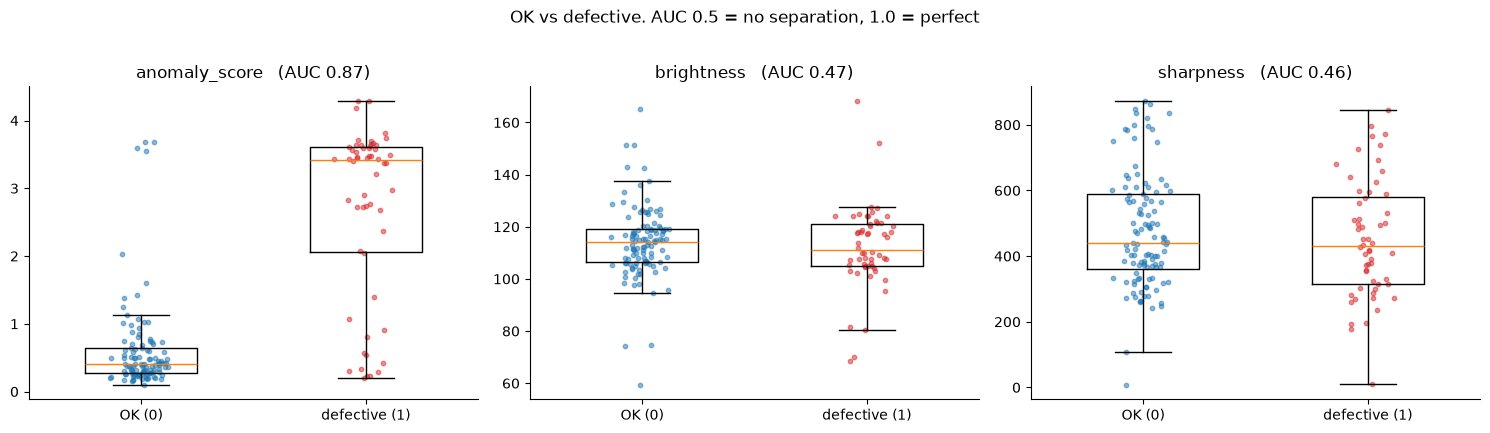

In [13]:
from sklearn.metrics import roc_auc_score

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col in zip(axes, ["anomaly_score", "brightness", "sharpness"]):
    data = [train.loc[train.inspector_label == k, col] for k in (0, 1)]
    ax.boxplot(data, widths=0.5, showfliers=False)
    for k, d in enumerate(data, start=1):
        ax.scatter(np.random.default_rng(0).normal(k, 0.06, len(d)), d, s=10, alpha=0.5,
                   color="tab:blue" if k == 1 else "tab:red")
    ax.set_xticks([1, 2], ["OK (0)", "defective (1)"])
    auc = roc_auc_score(train.inspector_label, train[col])
    ax.set_title(f"{col}   (AUC {auc:.2f})")
plt.suptitle("OK vs defective. AUC 0.5 = no separation, 1.0 = perfect", y=1.02); plt.tight_layout(); plt.show()

**Comparison:** `anomaly_score` separates the groups clearly (AUC ≈ 0.87): defective parts have a much higher median score.
Brightness and sharpness don't separate them at all (AUC ≈ 0.5), as expected: a defect changes a small area, while
whole-image statistics are dominated by capture conditions. *(These AUCs use all 168 labelled images; the template saw only
the development OK images. The honest held-out evaluation is in Part D.)*

Two groups don't fit the pattern: some **defective-labelled images with a low score**, and a few **OK-labelled images with a high score**.
Looking at them by defect type:

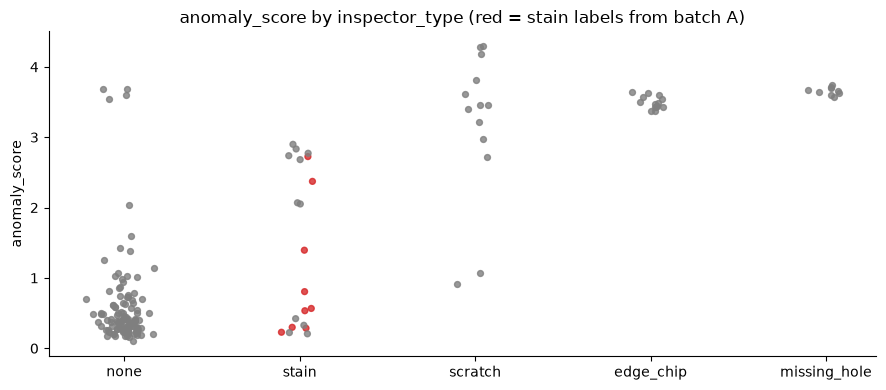

90th percentile of OK scores: 1.03  (a stain label scoring below it looks like an ordinary OK plate)


,stain_labels,scores_like_OK,stain_visible_in_image
batch,,,
BATCH-A,9,6,3
BATCH-B,4,3,1
BATCH-C,4,0,4
BATCH-D,3,1,2


In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
order = ["none", "stain", "scratch", "edge_chip", "missing_hole"]
for k, t in enumerate(order):
    s = train[train.inspector_type == t]
    colors = np.where(s.batch == "BATCH-A", "tab:red", "tab:gray") if t == "stain" else "tab:gray"
    ax.scatter(np.random.default_rng(1).normal(k, 0.08, len(s)), s.anomaly_score, s=18, c=colors, alpha=0.8)
ax.set_xticks(range(len(order)), order); ax.set_ylabel("anomaly_score")
ax.set_title("anomaly_score by inspector_type (red = stain labels from batch A)")
plt.tight_layout(); plt.show()

ok_max = train.loc[train.inspector_type == "none", "anomaly_score"].quantile(0.90)
st = train[train.inspector_type == "stain"].assign(visible=lambda d: d.anomaly_score >= ok_max)
print(f"90th percentile of OK scores: {ok_max:.2f}  (a stain label scoring below it looks like an ordinary OK plate)")
display(st.groupby("batch").agg(stain_labels=("image_id", "size"),
                                scores_like_OK=("visible", lambda v: int((~v).sum())),
                                stain_visible_in_image=("visible", "sum")))

Scratches, edge chips and missing holes almost always score high. **Stains split into two groups:** about half score
clearly high, and the other half score like OK plates. If only the stain labels with a clear image signal are counted,
batch A has about as many as the other batches, so **the batch A stain spike from Part A disappears**.
Here are the lowest-scoring stain labels next to the highest-scoring ones:

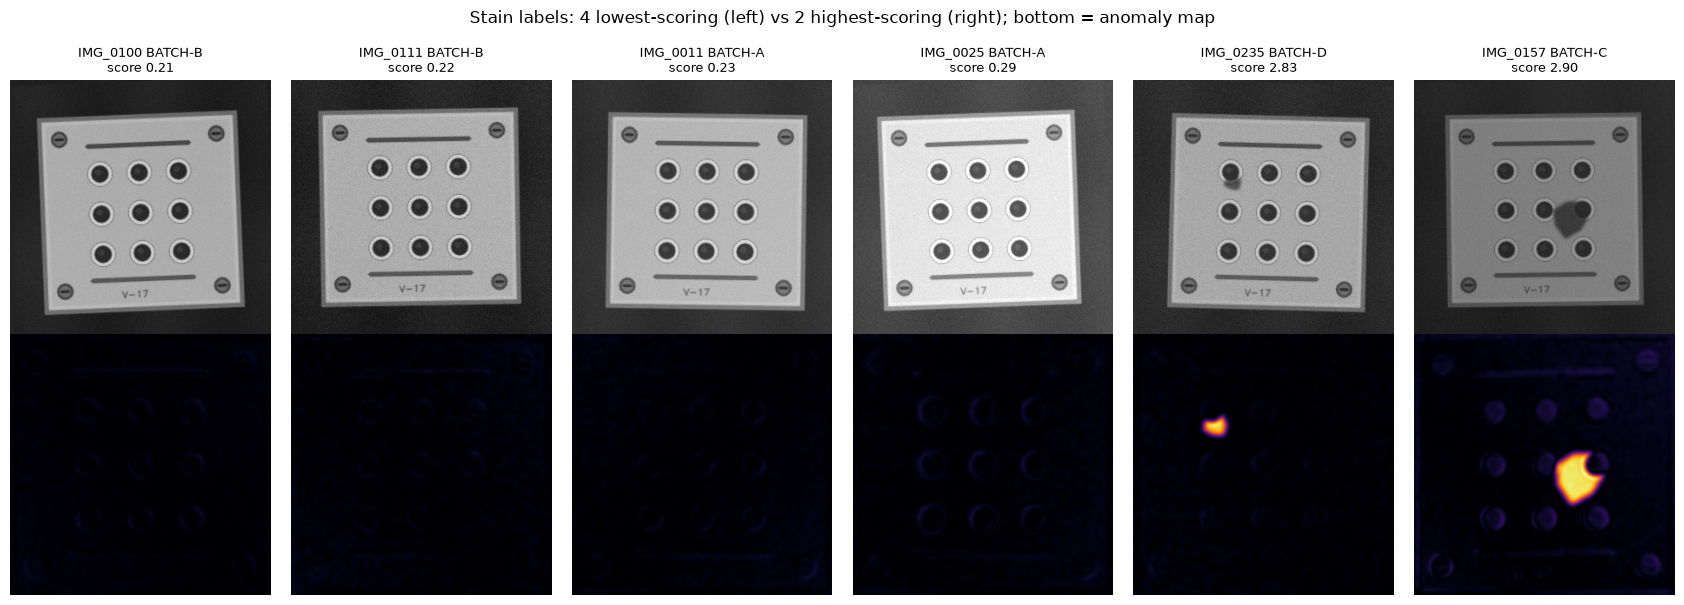

In [15]:
st_sorted = train[train.inspector_type == "stain"].sort_values("anomaly_score")
pick = pd.concat([st_sorted.head(4), st_sorted.tail(2)])
fig, axes = plt.subplots(2, 6, figsize=(17, 6))
for j, r in enumerate(pick.itertuples()):
    g = read_gray(r.file)
    axes[0, j].imshow(g, cmap="gray", vmin=0, vmax=255)
    axes[0, j].set_title(f"{r.image_id} {r.batch}\nscore {r.anomaly_score:.2f}", fontsize=9)
    axes[1, j].imshow(anomaly_map(g, TEMPLATE), cmap="inferno", vmin=0, vmax=3)
for a in axes.flat: a.axis("off")
plt.suptitle("Stain labels: 4 lowest-scoring (left) vs 2 highest-scoring (right); bottom = anomaly map", y=1.0)
plt.tight_layout(); plt.show()

**Follow-up on the Part A insight:** the low-scoring stain labels show **no visible stain**, either in the image or in the anomaly map,
while the high-scoring ones have an obvious dark blob. So a large part of batch A's stain spike most likely comes from the
**labels, not the parts**: the inspector seems to have over-marked stains on that day (or the stains are too faint to see in these images).
This can't be proven without re-inspecting the physical parts, but it matters for everything below:
**the training labels contain noise**, and a model can't be expected to "find" stains that aren't visible.

The noise goes the other way too. A few images labelled **OK** score as high as clear defects:

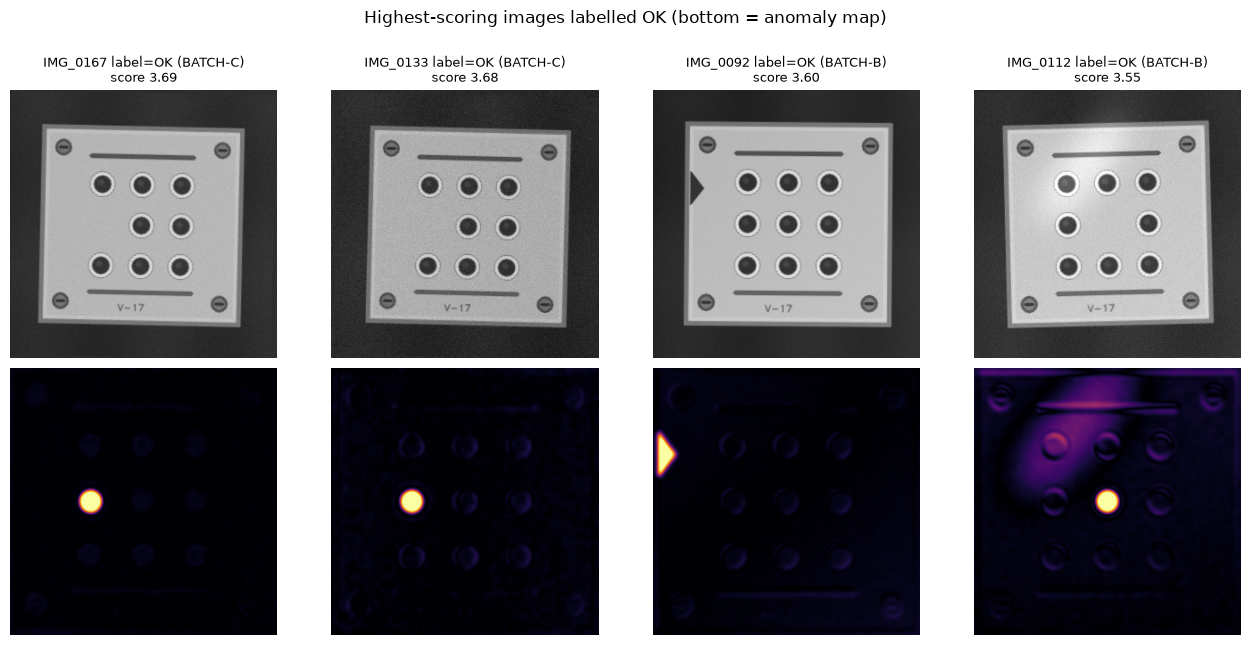

In [16]:
ok_high = train[train.inspector_label == 0].nlargest(4, "anomaly_score")
fig, axes = plt.subplots(2, 4, figsize=(13, 6.4))
for j, r in enumerate(ok_high.itertuples()):
    g = read_gray(r.file)
    axes[0, j].imshow(g, cmap="gray", vmin=0, vmax=255)
    axes[0, j].set_title(f"{r.image_id} label=OK ({r.batch})\nscore {r.anomaly_score:.2f}", fontsize=9)
    axes[1, j].imshow(anomaly_map(g, TEMPLATE), cmap="inferno", vmin=0, vmax=3)
for a in axes.flat: a.axis("off")
plt.suptitle("Highest-scoring images labelled OK (bottom = anomaly map)", y=1.0); plt.tight_layout(); plt.show()

These are **clear defects that the inspector labelled OK**: three plates are missing a hole (IMG_0167, 0133, 0112) and one has
an edge chip (IMG_0092). IMG_0112 also has a bright **glare spot** in the top-left, a lighting artifact that the anomaly map
picks up weakly, so capture conditions can add to the score too.

**Conclusion of Part B:** the labels are noisy in **both directions**: invisible "stains" labelled defective, and visible defects labelled OK.
Any validation metric computed against these labels will therefore *understate* how well an image-based detector really works.
When such images land in validation, they'll count as model errors even where the model is right.

### B4. Label verification: collecting the mismatches and reviewing them by hand

Steps:
1. Collect every labelled image where `anomaly_score` and the label strongly disagree.
2. Review each one by eye: **real defect**, **label error**, or **photo artifact**?
3. Store the result in new columns, `verified_label` and `verified_type` (the corrected defect type), plus the verdict
   and a comment. The original `inspector_label` / `inspector_type` are kept unchanged, and everything is saved to `train_verified.csv`.
4. Recompute ROC-AUC on the verified labels and compare it with the original labels.

**Mismatch rule:** the threshold is the 90th percentile of OK-labelled scores (≈1.03, from B3).
* labelled **defective** but score **below** the threshold (it looks like an OK plate), or
* labelled **OK** but score **at or above** the threshold.

Only `train.csv` images are reviewed. Test images are never labelled by hand (the brief forbids it).

threshold = 1.03   mismatches: 23 of 168 labelled images (11 labelled defective with a low score, 12 labelled OK with a high score)


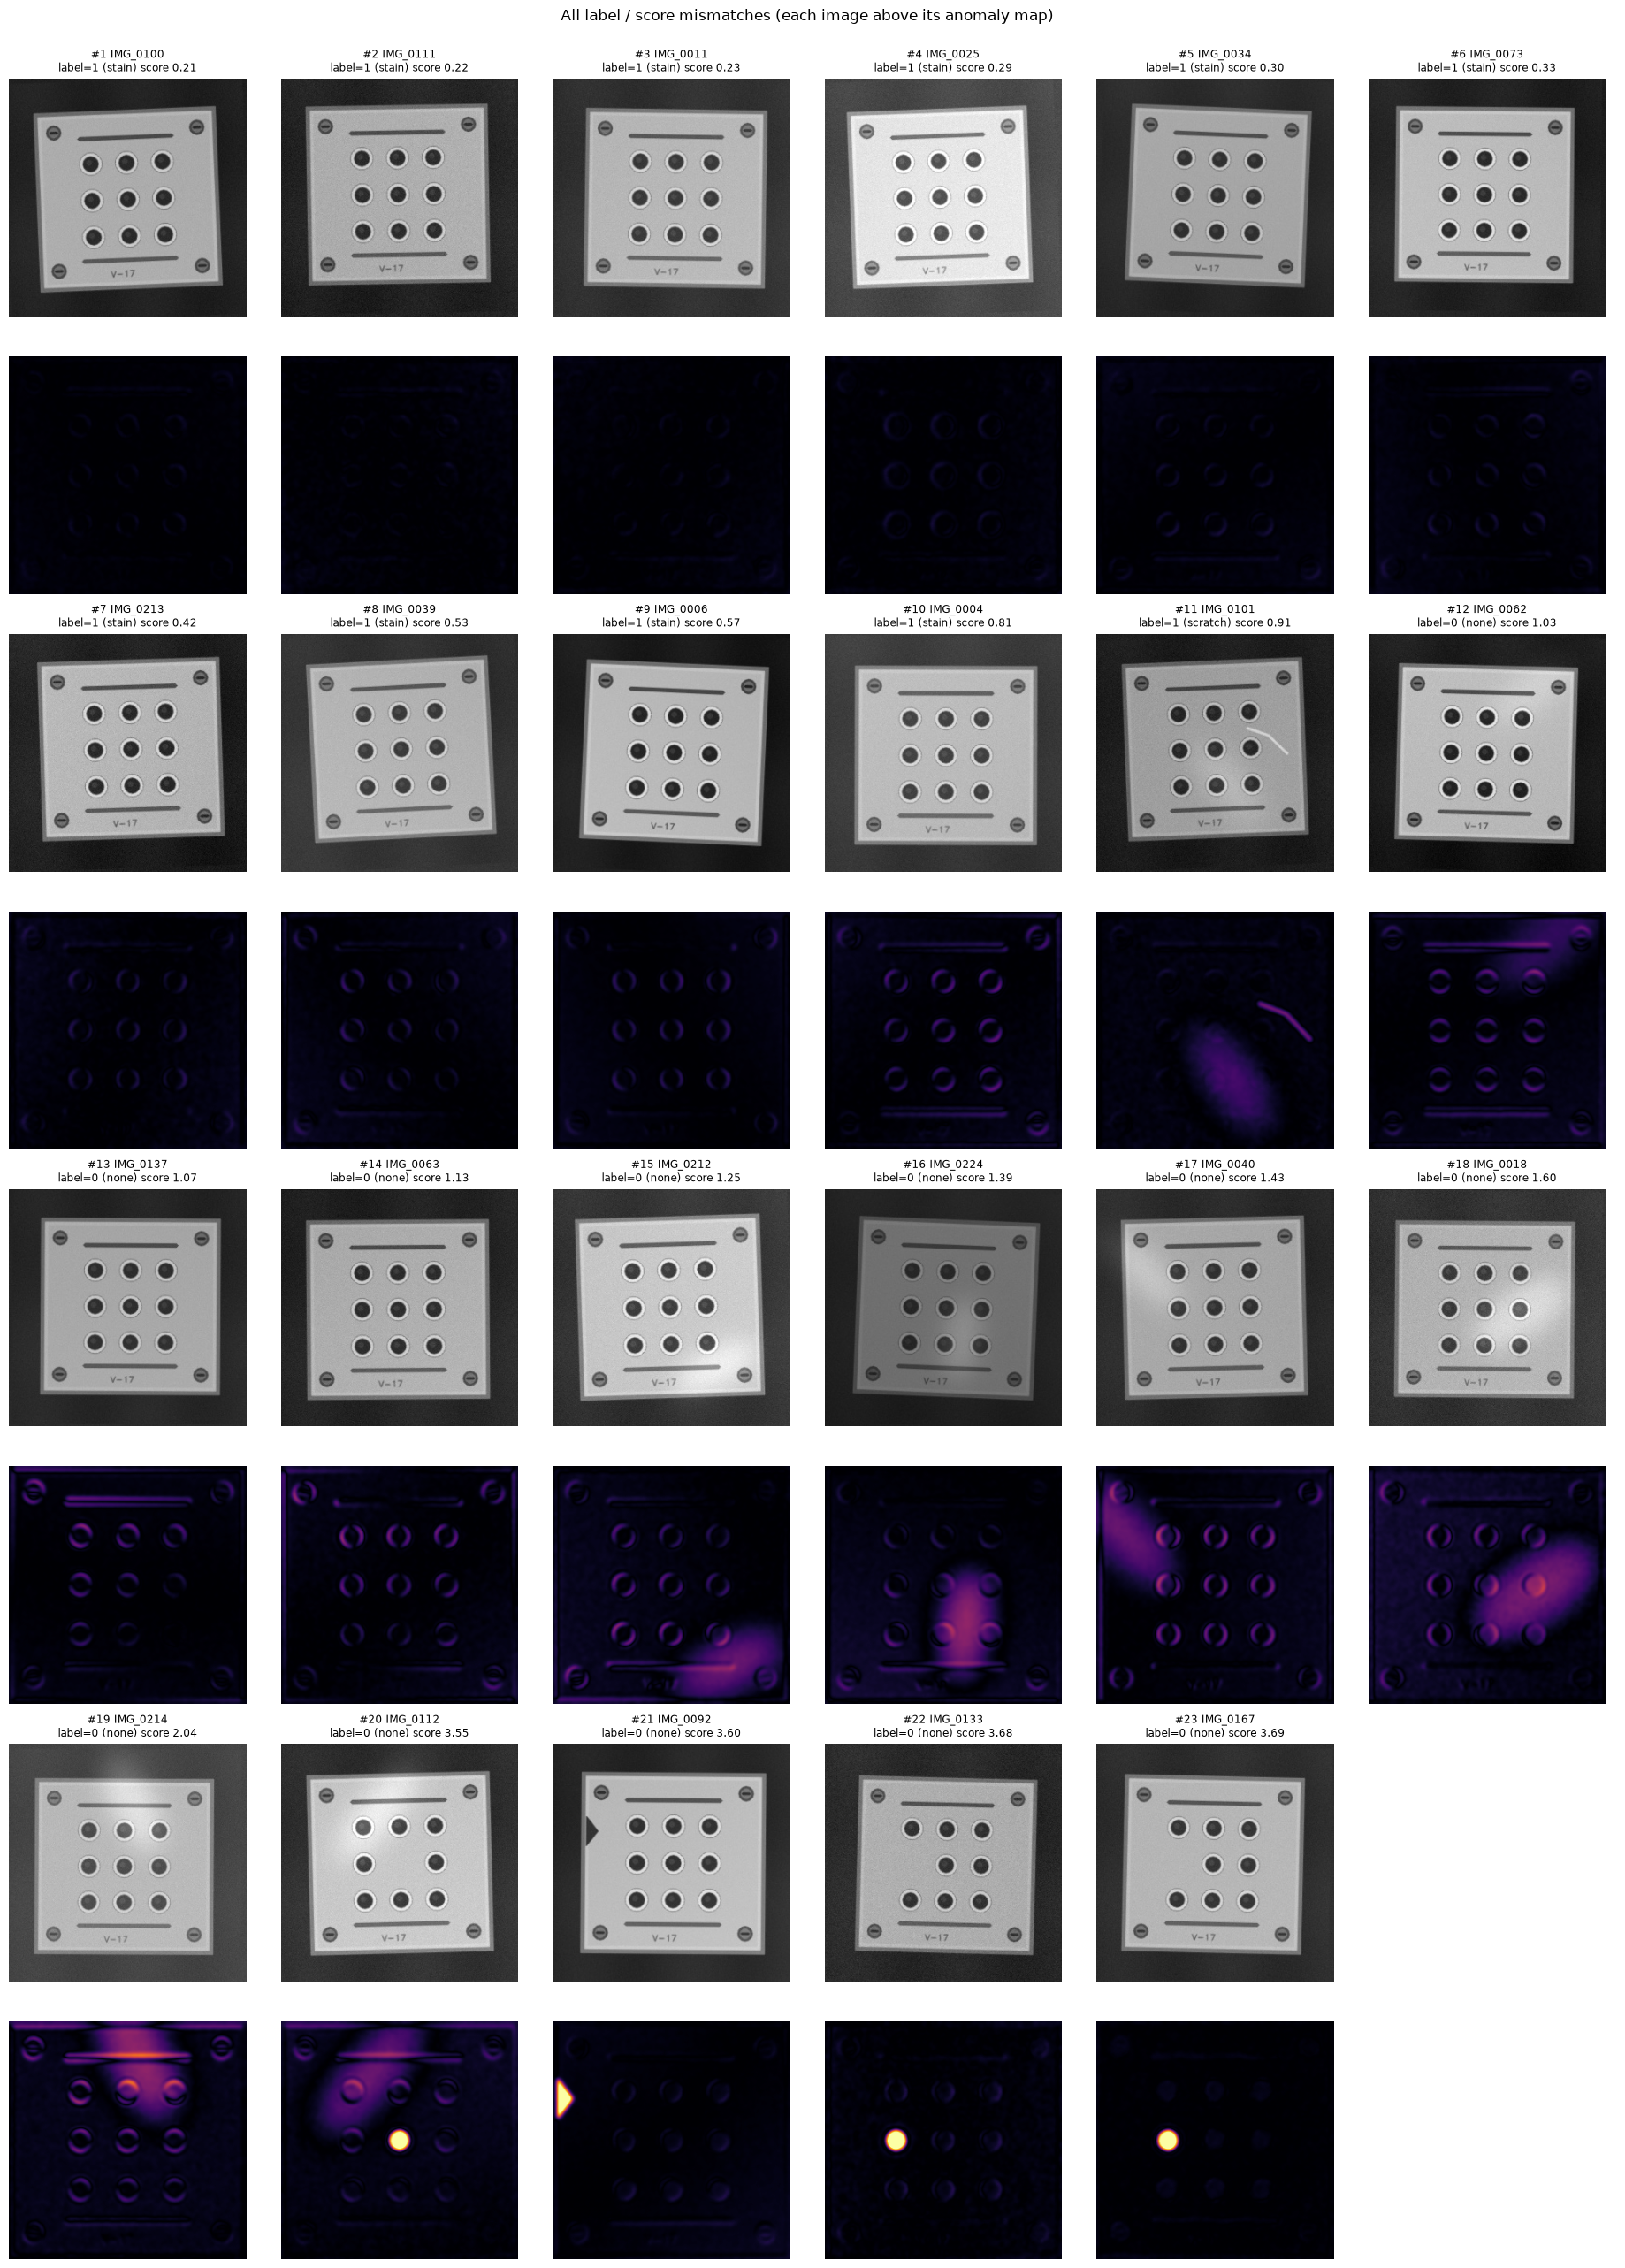

In [17]:
THR = train.loc[train.inspector_label == 0, "anomaly_score"].quantile(0.90)
mism = train[((train.inspector_label == 1) & (train.anomaly_score < THR)) |
             ((train.inspector_label == 0) & (train.anomaly_score >= THR))].copy()
mism = mism.sort_values(["inspector_label", "anomaly_score"], ascending=[False, True]).reset_index(drop=True)
print(f"threshold = {THR:.2f}   mismatches: {len(mism)} of {len(train)} labelled images "
      f"({(mism.inspector_label == 1).sum()} labelled defective with a low score, "
      f"{(mism.inspector_label == 0).sum()} labelled OK with a high score)")

per_row = 6
n_rows = int(np.ceil(len(mism) / per_row))
fig, axes = plt.subplots(2 * n_rows, per_row, figsize=(3.1 * per_row, 6.4 * n_rows))
for a in axes.flat: a.axis("off")
for k, r in enumerate(mism.itertuples()):
    row, col = 2 * (k // per_row), k % per_row
    g = read_gray(r.file)
    axes[row, col].imshow(g, cmap="gray", vmin=0, vmax=255)
    axes[row, col].set_title(f"#{k+1} {r.image_id}\nlabel={r.inspector_label} ({r.inspector_type}) score {r.anomaly_score:.2f}", fontsize=8.5)
    axes[row + 1, col].imshow(anomaly_map(g, TEMPLATE), cmap="inferno", vmin=0, vmax=3)
plt.suptitle("All label / score mismatches (each image above its anomaly map)", y=1.0)
plt.tight_layout(); plt.show()

**Review result** (each image was inspected by eye at full size, together with its anomaly map):

| group | images | label | what is visible | verdict | `verified_label` |
|---|---|---|---|---|---|
| invisible "stains" | IMG_0100, 0111, 0011, 0025, 0034, 0073, 0213, 0039, 0006, 0004 | 1 | no stain in the image, flat anomaly map | **label error** | 0 |
| thin scratch | IMG_0101 | 1 | a real short, thin scratch (plus a glare patch) | **real defect** (a model miss) | 1 |
| missed defects | IMG_0167, 0133, 0112 (missing hole), IMG_0092 (edge chip) | 0 | the defect is clearly visible | **label error** | 1 |
| glare / lighting | IMG_0214, 0018, 0040, 0224, 0212, 0063, 0137, 0062 | 0 | bright glare or lighting spots; the part itself looks fine | **photo artifact** (a model weakness) | 0 |

Caveat for the invisible stains: a very faint stain might fall below what this camera captures (e.g. IMG_0025 is overexposed).
"Not visible in the image" is the best judgement available from the data, not a physical re-inspection.

In [18]:
# image_id -> (verdict, verified_label, verified_type, comment)
REVIEW = {
    **{i: ("label_error", 0, "none", "labelled stain, but no stain visible; flat anomaly map")
       for i in ["IMG_0100", "IMG_0111", "IMG_0011", "IMG_0025", "IMG_0034",
                 "IMG_0073", "IMG_0213", "IMG_0039", "IMG_0006", "IMG_0004"]},
    "IMG_0101": ("real_defect", 1, "scratch", "real thin scratch; low score is a model miss"),
    **{i: ("label_error", 1, "missing_hole", "labelled OK, but a hole is clearly missing")
       for i in ["IMG_0167", "IMG_0133", "IMG_0112"]},
    "IMG_0092": ("label_error", 1, "edge_chip", "labelled OK, but the plate edge is clearly chipped"),
    **{i: ("photo_artifact", 0, "none", "glare / lighting spot raises the score; part looks fine")
       for i in ["IMG_0214", "IMG_0018", "IMG_0040", "IMG_0224",
                 "IMG_0212", "IMG_0063", "IMG_0137", "IMG_0062"]},
}
assert set(REVIEW) == set(mism.image_id), "every mismatch must have a review decision (and nothing else)"

# New columns: the original inspector_label / inspector_type are kept unchanged.
rv = lambda i, k, default: REVIEW[i][k] if i in REVIEW else default
train["review"] = [rv(i, 0, "not_reviewed") for i in train.image_id]
train["verified_label"] = [rv(i, 1, lab) for i, lab in zip(train.image_id, train.inspector_label)]
train["verified_type"] = [rv(i, 2, t) for i, t in zip(train.image_id, train.inspector_type)]
train["review_comment"] = [rv(i, 3, "") for i in train.image_id]
train["label_changed"] = train.verified_label != train.inspector_label

print("All reviewed images: original vs corrected")
cols = ["image_id", "batch", "split", "anomaly_score", "inspector_label", "inspector_type",
        "verified_label", "verified_type", "review", "review_comment"]
reviewed = train[train.review != "not_reviewed"].sort_values(["review", "image_id"])[cols]
display(reviewed.style.format({"anomaly_score": "{:.2f}"})
        .apply(lambda r: ["background-color:#fde2c8" if train.set_index("image_id").loc[r.image_id, "label_changed"] else ""] * len(r), axis=1)
        .hide(axis="index"))

All reviewed images: original vs corrected


image_id,batch,split,anomaly_score,inspector_label,inspector_type,verified_label,verified_type,review,review_comment
IMG_0004,BATCH-A,dev,0.81,1,stain,0,none,label_error,"labelled stain, but no stain visible; flat anomaly map"
IMG_0006,BATCH-A,dev,0.57,1,stain,0,none,label_error,"labelled stain, but no stain visible; flat anomaly map"
IMG_0011,BATCH-A,dev,0.23,1,stain,0,none,label_error,"labelled stain, but no stain visible; flat anomaly map"
IMG_0025,BATCH-A,val,0.29,1,stain,0,none,label_error,"labelled stain, but no stain visible; flat anomaly map"
IMG_0034,BATCH-A,dev,0.30,1,stain,0,none,label_error,"labelled stain, but no stain visible; flat anomaly map"
IMG_0039,BATCH-A,val,0.53,1,stain,0,none,label_error,"labelled stain, but no stain visible; flat anomaly map"
IMG_0073,BATCH-B,dev,0.33,1,stain,0,none,label_error,"labelled stain, but no stain visible; flat anomaly map"
IMG_0092,BATCH-B,dev,3.60,0,none,1,edge_chip,label_error,"labelled OK, but the plate edge is clearly chipped"
IMG_0100,BATCH-B,dev,0.21,1,stain,0,none,label_error,"labelled stain, but no stain visible; flat anomaly map"
IMG_0111,BATCH-B,val,0.22,1,stain,0,none,label_error,"labelled stain, but no stain visible; flat anomaly map"


In [19]:
display(pd.crosstab(train.inspector_label, train.verified_label, rownames=["inspector_label"], colnames=["verified_label"], margins=True))
display(pd.crosstab(train.inspector_type, train.verified_type, rownames=["inspector_type"], colnames=["verified_type"], margins=True))
print("changed labels by split:", train[train.label_changed].split.value_counts().to_dict())

# Save the corrected labels next to the original data (train.csv itself is not modified).
out_cols = list(pd.read_csv(DATA_DIR / "train.csv").columns) + ["verified_label", "verified_type", "review", "review_comment"]
train[out_cols].sort_values("image_id").to_csv(DATA_DIR / "train_verified.csv", index=False)
print(f"saved train_verified.csv: {len(train)} rows, {int(train.label_changed.sum())} labels corrected")

verified_label,0,1,All
inspector_label,,,
0,108,4,112
1,10,46,56
All,118,50,168


verified_type,edge_chip,missing_hole,none,scratch,stain,All
inspector_type,,,,,,
edge_chip,14,0,0,0,0,14
missing_hole,0,9,0,0,0,9
none,1,3,108,0,0,112
scratch,0,0,0,13,0,13
stain,0,0,10,0,10,20
All,15,12,118,13,10,168


changed labels by split: {'dev': 11, 'val': 3}
saved train_verified.csv: 168 rows, 14 labels corrected


,AUC vs inspector_label,AUC vs verified_label
set,,
all labelled (168),0.868,0.996
validation split only (51),0.877,1.000


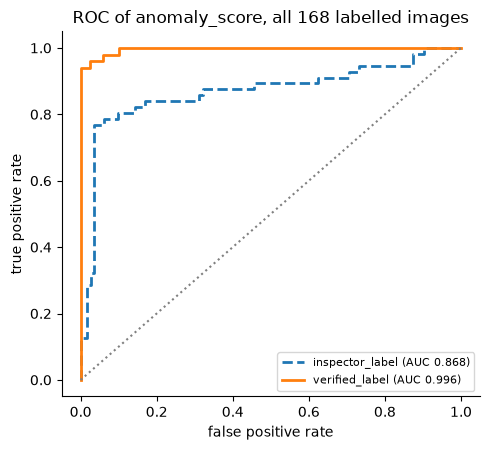

In [20]:
from sklearn.metrics import roc_curve

def auc_table(df):
    rows = []
    for name, sub in [("all labelled (168)", df), ("validation split only (51)", df[df.split == "val"])]:
        rows.append({"set": name,
                     "AUC vs inspector_label": roc_auc_score(sub.inspector_label, sub.anomaly_score),
                     "AUC vs verified_label": roc_auc_score(sub.verified_label, sub.anomaly_score)})
    return pd.DataFrame(rows).set_index("set")

auc_before_after = auc_table(train)
display(auc_before_after.style.format("{:.3f}"))

fig, ax = plt.subplots(figsize=(5, 4.6))
for col, ls in [("inspector_label", "--"), ("verified_label", "-")]:
    fpr, tpr, _ = roc_curve(train[col], train.anomaly_score)
    ax.plot(fpr, tpr, ls, lw=2, label=f"{col} (AUC {roc_auc_score(train[col], train.anomaly_score):.3f})")
ax.plot([0, 1], [0, 1], ":", color="gray")
ax.set_xlabel("false positive rate"); ax.set_ylabel("true positive rate")
ax.set_title("ROC of anomaly_score, all 168 labelled images"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

**Before vs after label correction:** with the verified labels, the anomaly score is close to a perfect ranking. Most of the
"errors" against the original labels were **label errors, not model errors**: 14 of 168 labels (8 %) changed.
The remaining disagreements are real model weaknesses: a thin scratch that scores low, and glare spots that score high.

**Read this improvement with care. It is optimistic by construction:** only images where the model disagreed with the label
were reviewed, so any change can only move the label *toward* the model. Images the model and the inspector got wrong *together*
(e.g. a faint defect both missed) were never looked at. The real performance lies somewhere between the two numbers.
A fair estimate would need a random sample reviewed blind, without looking at the score.

**How the verified labels are used next:** Part C trains on `verified_label`, because training on known-wrong labels would teach
the model that a missing hole is OK. Part D reports validation metrics against **both** label sets, so the effect stays visible.
(The template still includes the 4 missed defects among its 78 "OK" plates. The pixel-wise median is robust to a few outliers,
so they don't distort it.)